# Más allá: estabilidad del capital medida sobre historias independientes de verdad conocida

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 02, 06 y 07 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- describir el diseño del experimento de estabilidad del caso C17: cuatro índices de cola, dos largos de historia, dos umbrales de recolección, 1.000 historias independientes por celda, un cuantil verdadero conocido;
- leer, desde los documentos versionados, la dispersión, el sesgo, la proporción de historias que subestiman y el número de historias en que cada estimador está definido;
- reproducir el efecto del largo de la historia sobre la dispersión con historias nuevas y la prueba `oprisk.capital_stability` del motor;
- medir con qué frecuencia un banco concluiría, desde sus propios datos, que la media de sus pérdidas es infinita o finita cuando no lo es;
- decir con precisión qué afirma la declaración BS-12, cuál es su evidencia y qué no afirma.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este cuaderno carga esos módulos por su ruta (importar todo el paquete `pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Las cuatro variantes del caso C17 (índices de cola 0,6, 0,8, 0,96 y 1,1) del banco sintético.

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json`: `outputs.cells` (por celda, las semillas de las replicaciones y el resumen de cada estimador sobre 1.000 historias, y el perfil del índice de cola ajustado), `outputs.truth` (los parámetros verdaderos y el cuantil verdadero con su verificación Monte Carlo) y `tests` (las filas versionadas de `oprisk.capital_stability`).
- **Qué está versionado y qué no:** los documentos guardan los resúmenes de 16.000 historias, no las historias. Las historias nuevas se generan con el generador del caso, cargado por su ruta como en el cuaderno 02, con semillas fuera de los rangos versionados.
- **Qué es sintético:** el banco, sus pérdidas y los escenarios. La severidad es exactamente Pareto generalizada sobre EUR 10.000, con la escala ajustada a medianas publicadas del ejercicio de datos de pérdida de 2008 del Comité de Basilea (BCBS, 2009, `derived-only`).

La celda siguiente carga los documentos y el generador.

In [2]:
# Load the four variant documents and the case's generator and estimator by path
ROOT = Path("../../..").resolve()
docs = {name: json.loads((ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")}
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params, replicate

print("variantes:", list(docs), "| calculado por riskvalidation", {d["provenance"]["riskvalidation_version"] for d in docs.values()}, "| instalado", md.version("riskvalidation"))

variantes: ['xi-0-6', 'xi-0-8', 'xi-0-96', 'xi-1-1'] | calculado por riskvalidation {'0.7.0'} | instalado 0.8.1


## Método

### Paso 1: el diseño

El experimento cruza cuatro índices de cola, dos largos de historia (5 y 10 años) y dos umbrales de recolección (EUR 10.000 y 20.000): 16 celdas. En cada celda el caso simula 1.000 historias desde rangos de semillas disjuntos, de modo que las historias son independientes, registra solo las pérdidas sobre el umbral de la celda y corre cada estimador de la escalera sobre cada una. El cuantil de 99,9% verdadero de la pérdida anual de cada variante se conoce por construcción: el método de Fourier en una grilla fina, verificado con un Monte Carlo de 10.000.000 de años. La celda siguiente verifica desde los documentos que los 16 rangos de semillas no se solapan, e imprime la verificación Monte Carlo de cada verdad.

In [3]:
# Check that the 16 seed ranges are disjoint and read the Monte Carlo check of each true quantile
ranges = []
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        rep = cell["replications"]
        ranges.append((rep["seed_first"], rep["seed_first"] + rep["n_replications"], name, cell["id"]))
ranges.sort()
overlaps = [(a[2:], b[2:]) for a, b in zip(ranges, ranges[1:]) if a[1] > b[0]]
print("celdas:", len(ranges), "| historias:", sum(r[1] - r[0] for r in ranges), "| rangos de semillas solapados:", len(overlaps), "| replicaciones fallidas:", sum(c["replications"]["n_failed"] for d in docs.values() for c in d["outputs"]["cells"]))
for name, doc in docs.items():
    q = doc["outputs"]["truth"]["annual_loss_quantile"]
    print("%-8s cuantil verdadero %15s | verificación Monte Carlo %15s +/- %12s (%.2f%%) | coincide a 3 se %s"
          % (name, format(q["value_eur"], ",.0f"), format(q["mc_check"]["value_eur"], ",.0f"), format(q["mc_check"]["standard_error_eur"], ",.0f"), 100 * q["mc_check"]["standard_error_eur"] / q["value_eur"], q["mc_check"]["agrees"]))

celdas: 16 | historias: 16000 | rangos de semillas solapados: 0 | replicaciones fallidas: 0
xi-0-6   cuantil verdadero      33,897,000 | verificación Monte Carlo      33,806,597 +/-      173,397 (0.51%) | coincide a 3 se True
xi-0-8   cuantil verdadero     163,483,000 | verificación Monte Carlo     162,770,645 +/-    1,238,015 (0.76%) | coincide a 3 se True
xi-0-96  cuantil verdadero     634,865,452 | verificación Monte Carlo     629,494,317 +/-    5,917,877 (0.93%) | coincide a 3 se True
xi-1-1   cuantil verdadero   2,148,602,460 | verificación Monte Carlo   2,119,449,230 +/-   21,331,165 (0.99%) | coincide a 3 se True


### Paso 2: qué se mide en cada historia

Para un estimador con capital $\hat C_k$ en la historia $k$, los resúmenes versionados sobre las 1.000 historias son, relativos al cuantil verdadero $C^\star$:

$$\text{sesgo} = \operatorname{mediana}_k(\hat C_k / C^\star) - 1, \qquad \text{dispersión} = \big(Q_{75} - Q_{25}\big)\big(\hat C_k / C^\star\big), \qquad \text{subestimación} = \frac{1}{1000}\sum_k \mathbf 1\{\hat C_k < C^\star\}$$

junto con el número de historias en que el estimador devuelve un número: un ajuste que no converge, una grilla que no alcanza el cuantil o una media que no existe no da capital, nunca un número de relleno. `oprisk.capital_stability`, del motor, calcula los dos primeros desde un arreglo de capitales. La celda siguiente lee el estimador de empalme para las cuatro variantes y las cuatro celdas e imprime las cuatro cantidades.

In [4]:
# The splice estimator in the 16 cells: bias, dispersion, share of underestimating histories, histories with a capital
print("%-8s %-11s %9s %11s %14s %9s" % ("", "", "sesgo", "dispersión", "subestima", "definido"))
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        splice = cell["capital"]["lda_splice"]
        print("%-8s %-11s %+9.3f %11.3f %14.3f %9d" % (name, cell["id"], splice["ratio_to_truth"]["median"] - 1.0, splice["iqr_over_truth"], splice["share_underestimating"], splice["n_defined"]))

                         sesgo  dispersión      subestima  definido
xi-0-6   y5-h10000      -0.236       1.952          0.558       959
xi-0-6   y5-h20000      -0.236       2.033          0.584       771
xi-0-6   y10-h10000     -0.150       1.429          0.559       996
xi-0-6   y10-h20000     -0.160       1.354          0.568       859
xi-0-8   y5-h10000      -0.337       2.744          0.587       904
xi-0-8   y5-h20000      -0.361       2.560          0.604       682
xi-0-8   y10-h10000     -0.184       1.776          0.552       971
xi-0-8   y10-h20000     -0.091       1.983          0.530       727
xi-0-96  y5-h10000      -0.219       3.104          0.566       725
xi-0-96  y5-h20000      -0.373       3.299          0.560       550
xi-0-96  y10-h10000     -0.236       2.111          0.546       818
xi-0-96  y10-h20000     -0.071       2.228          0.530       572
xi-1-1   y5-h10000      -0.502       3.304          0.568       229
xi-1-1   y5-h20000      -0.280       3.184      

### Paso 3: el efecto del largo de la historia, con historias nuevas

Los resúmenes versionados dicen que la dispersión baja cuando la historia pasa de 5 a 10 años. Podemos verificarlo con historias que el caso nunca usó, y con la prueba propia del motor. La celda siguiente sortea 40 historias independientes nuevas (semillas desde 9.000.000) de la variante con índice de cola 0,8 para cada uno de los dos largos con un umbral de EUR 10.000, corre el estimador del caso (unos 35 segundos en total) y aplica `oprisk.capital_stability` a los capitales del empalme y a la aproximación de pérdida única, frente al cuantil verdadero. Registra además el primer valor de cada perfil del índice de cola ajustado, el del umbral de recolección. Con solo 40 historias los cuartiles son ruidosos; las filas versionadas con 1.000 historias se imprimen a su lado.

In [5]:
# Fresh independent histories of the variant with tail index 0.8, 5 and 10 years, threshold EUR 10,000
doc08 = docs["xi-0-8"]
variant = generator.variant(0.8)
bi = doc08["outputs"]["bank"]["business_indicator"]["bi_eur"]
true_q = doc08["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
fresh = {}
for years in (5, 10):
    fresh[years] = [replicate.estimate(variant, 9_000_000 + 1000 * years + k, years, 10_000.0, bi, None, 20_000) for k in range(40)]
print("%-6s %-6s %5s %11s %9s %8s | %s" % ("años", "peldaño", "n", "dispersión", "sesgo", "luz", "versionada sobre 1000: dispersión, sesgo"))
for years in (5, 10):
    for rung in ("lda_splice", "sla"):
        capitals = np.array([r[rung] for r in fresh[years]])
        capitals = capitals[np.isfinite(capitals)]
        result = oprisk_tests.capital_stability(capitals, true_q, model_id=rung)
        cell = next(c for c in doc08["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)
        committed = cell["capital"][rung]
        print("%-6d %-6s %5d %11.3f %+9.3f %8s | %.3f %+.3f" % (years, rung, capitals.size, result.metric, result.statistic, result.light.value, committed["iqr_over_truth"], committed["ratio_to_truth"]["median"] - 1.0))

años   peldaño     n  dispersión     sesgo      luz | versionada sobre 1000: dispersión, sesgo
5      lda_splice    37       6.116    +0.460      red | 2.744 -0.337
5      sla       40       1.915    +0.146      red | 1.284 -0.082
10     lda_splice    39       1.142    -0.305      red | 1.776 -0.184
10     sla       40       0.773    +0.063      red | 0.823 -0.075


### Paso 4: ¿con qué frecuencia un banco concluye algo errado sobre la media?

Un índice de cola de 1 o más significa que la pérdida anual media no existe. Los documentos registran, para cada celda, la proporción de historias cuyo índice de cola Pareto generalizado, ajustado en el umbral de recolección, es 1 o más (`share_at_least_one`). Es la probabilidad de que un banco con ese largo de historia concluya, solo con sus datos, que su pérdida media es infinita. La celda siguiente la imprime para las 16 celdas, junto a la proporción que concluye lo contrario cuando la verdad es 1 o más.

In [6]:
# The share of histories whose fitted tail index reaches 1, in the 16 cells (profile at the collection threshold)
print("%-8s %-11s %9s %-30s" % ("", "", "xi >= 1", "conclusión errada"))
for name, doc in docs.items():
    true_xi = doc["outputs"]["tail_index"]
    for cell in doc["outputs"]["cells"]:
        share = cell["threshold_stability"][0]["share_at_least_one"]
        wrong = share if true_xi < 1 else 1.0 - share
        verdict = "concluye media infinita" if true_xi < 1 else "concluye media finita"
        print("%-8s %-11s %9.3f %-30s %.3f" % (name, cell["id"], share, verdict, wrong))

                       xi >= 1 conclusión errada             
xi-0-6   y5-h10000       0.000 concluye media infinita        0.000
xi-0-6   y5-h20000       0.000 concluye media infinita        0.000
xi-0-6   y10-h10000      0.000 concluye media infinita        0.000
xi-0-6   y10-h20000      0.000 concluye media infinita        0.000
xi-0-8   y5-h10000       0.024 concluye media infinita        0.024
xi-0-8   y5-h20000       0.063 concluye media infinita        0.063
xi-0-8   y10-h10000      0.005 concluye media infinita        0.005
xi-0-8   y10-h20000      0.012 concluye media infinita        0.012
xi-0-96  y5-h10000       0.332 concluye media infinita        0.332
xi-0-96  y5-h20000       0.344 concluye media infinita        0.344
xi-0-96  y10-h10000      0.268 concluye media infinita        0.268
xi-0-96  y10-h20000      0.317 concluye media infinita        0.317
xi-1-1   y5-h10000       0.818 concluye media finita          0.182
xi-1-1   y5-h20000       0.732 concluye media finita  

### Paso 5: de dónde no viene la inestabilidad

La dispersión podría venir en principio de la simulación usada para construir la verdad o de los estimadores, y no de los datos. La verificación Monte Carlo de la verdad tiene un error estándar bajo 1% del cuantil (paso 1), los peldaños de empalme y de Panjer no tienen Monte Carlo alguno, y el caso registra que las agregaciones de Panjer y de Fourier de la misma ley ajustada coinciden en las historias donde existen ambas (`aggregation_agreement`). Así que la dispersión de decenas o cientos de por ciento viene de estimar la cola con 5 o 10 años de pérdidas. La celda siguiente imprime la mayor diferencia relativa entre Panjer y Fourier en las celdas, y el número de historias comparadas.

In [7]:
# The agreement between the Panjer and Fourier aggregations of the same fitted law, over the 16 cells
agreements = [c["aggregation_agreement"] for d in docs.values() for c in d["outputs"]["cells"]]
print("mayor diferencia relativa Panjer - Fourier:", max(a["max_rel_diff_panjer_fft"] for a in agreements), "| historias comparadas:", sum(a["n_compared"] for a in agreements))

mayor diferencia relativa Panjer - Fourier: 0.000968054211 | historias comparadas: 11552


## Estado del arte

Lo que se sabe antes de este cuaderno, desde los cuadernos y fuentes de este tema. El capital de riesgo operacional por el enfoque de distribución de pérdidas (LDA) es un cuantil alto de una suma compuesta cuya cola se estima con pocos años de pérdidas recolectadas sobre un umbral (cuadernos 01 y 02; Chavez-Demoulin, Embrechts y Neslehova, 2006; Shevchenko, 2010). Se sabe que el error del cuantil Monte Carlo decae como la raíz cuadrada del número de años simulados (Shevchenko, 2010). El Comité de Basilea eliminó el enfoque avanzado por su complejidad y la falta de comparabilidad de los modelos internos (BCBS, 2016), y la crítica académica a su reemplazo argumentó que el enfoque estándar es a su vez inestable e insensible al riesgo (Peters, Shevchenko, Hassani y Chapelle, 2016). La investigación detrás de este caso ilustra la inestabilidad de un LDA cerca de un índice de cola de 1 con una calibración de las medianas de datos de pérdida de 2008 del Comité de Basilea (BCBS, 2009), con salvedades. Lo que esas fuentes no entregan, hasta donde halló la investigación, es la dispersión del capital LDA frente a una verdad conocida, medida sobre muchas historias independientes y varios índices de cola, largos de historia y umbrales.

## Más allá del estado del arte

**Declaración BS-12: la inestabilidad del capital de riesgo operacional, medida sobre historias independientes de verdad conocida.**

- **Qué agrega.** Para cuatro índices de cola (0,6, 0,8, 0,96 y 1,1), dos largos de historia (5 y 10 años) y dos umbrales de recolección (EUR 10.000 y 20.000), el caso simula 1.000 historias independientes por celda en rangos de semillas disjuntos (16.000 historias). Para cada peldaño de una escalera de estimación de seis peldaños y para el enfoque estándar registra el capital de 99,9% frente al cuantil anual de pérdida verdadero del generador, como la mediana sobre la verdad, el rango intercuartil sobre la verdad, la proporción de historias que subestiman y el número de historias en que el peldaño está definido; y la proporción de historias cuyo índice de cola ajustado llega a 1, es decir, que concluirían una media infinita. En la grilla versionada el rango intercuartil del peldaño de empalme es de 1,35 a 3,30 veces la verdad, las 92 filas de `oprisk.capital_stability` son rojas frente a umbrales internos declarados, entre 27% y 34% de las historias de la variante con índice de cola 0,96 concluyen una media infinita que no existe, y entre 9% y 27% de las de la variante con índice de cola 1,1 concluyen una finita.
- **Evidencia.** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json` (`outputs.cells`, `outputs.truth`, `tests`), los requisitos CT-1701 a CT-1715 de `docs/design/features/c17/requirements.md`, y este cuaderno, que verifica el diseño, reproduce el efecto del largo con historias nuevas y con la prueba del motor, e imprime los números.
- **La práctica a la que supera.** La investigación presenta la inestabilidad cerca de un índice de cola de 1 como un caso didáctico a partir de una calibración ilustrativa, con salvedades; el Comité de Basilea da la complejidad y la falta de comparabilidad, no una medición de error, como su razón para eliminar el enfoque avanzado; la crítica académica argumenta la inestabilidad del enfoque estándar. Ninguna de las fuentes halladas mide la dispersión del capital LDA frente a una verdad conocida sobre historias independientes. Esa ausencia es UNVERIFIED más allá de la búsqueda de la propia investigación.
- **Lo que la declaración no dice.** No dice que el LDA sea inutilizable ni que el enfoque estándar tenga razón: el enfoque estándar no está calibrado a un cuantil de 99,9% y aquí solo se compara con el del generador. Trata de un banco sintético cuya severidad se sortea de la familia que suponen los estimadores de cola (lo que favorece a los estimadores) y cuyas luces usan los umbrales propios de Contraste; no dice nada sobre el capital de ningún banco real.

In [8]:
# The evidence of the claim in one table: the splice and the standardised approach in the 10-year cells, and the wrong conclusions about the mean
print("%-8s %-11s %12s %12s %10s %10s %12s" % ("", "", "RIC empalme", "definido", "SMA / verdad", "xi >= 1", "xi verdadero"))
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        if not cell["id"].startswith("y10"):
            continue
        print("%-8s %-11s %12.3f %12d %10.3f %10.3f %12s" % (name, cell["id"], cell["capital"]["lda_splice"]["iqr_over_truth"], cell["capital"]["lda_splice"]["n_defined"], cell["sma"]["orc_over_true_quantile"]["median"], cell["threshold_stability"][0]["share_at_least_one"], doc["outputs"]["tail_index"]))
rows = [t for d in docs.values() for t in d["tests"] if t["test_id"] == "oprisk.capital_stability"]
print("filas versionadas de estabilidad del capital:", len(rows), "| rojas:", sum(t["light"] == "red" for t in rows), "| filas con valor p:", sum(t["p_value"] is not None for t in rows))

                      RIC empalme     definido SMA / verdad    xi >= 1 xi verdadero
xi-0-6   y10-h10000         1.429          996      4.030      0.000          0.6
xi-0-6   y10-h20000         1.354          859      3.975      0.000          0.6
xi-0-8   y10-h10000         1.776          971      0.882      0.005          0.8
xi-0-8   y10-h20000         1.983          727      0.869      0.012          0.8
xi-0-96  y10-h10000         2.111          818      0.242      0.268         0.96
xi-0-96  y10-h20000         2.228          572      0.239      0.317         0.96
xi-1-1   y10-h10000         1.683          128      0.078      0.912          1.1
xi-1-1   y10-h20000         2.319          409      0.077      0.836          1.1
filas versionadas de estabilidad del capital: 92 | rojas: 92 | filas con valor p: 0


La última celda dibuja la evidencia de la declaración. A la izquierda, el rango intercuartil del capital del empalme sobre la verdad para cada índice de cola, con 5 y con 10 años de datos, desde las celdas versionadas con umbral de EUR 10.000: el rango es del orden de la verdad misma y baja solo despacio con diez años. A la derecha, la proporción de historias que concluyen una media infinita, para cada índice de cola y largo: es pequeña con 0,6 y 0,8, entre un cuarto y un tercio cerca de 0,96, y la gran mayoría con 1,1.

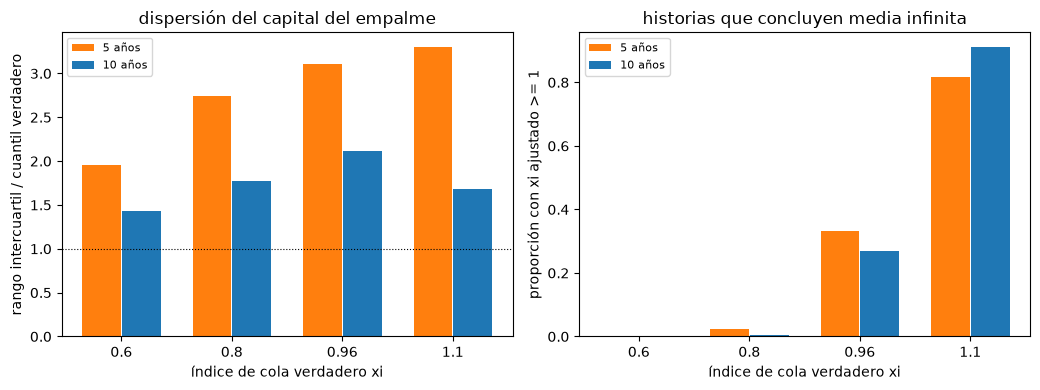

In [9]:
# Draw the dispersion of the splice capital and the share of histories that conclude an infinite mean
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
labels = [str(d["outputs"]["tail_index"]) for d in docs.values()]
positions = np.arange(len(labels))
for offset, years, color in ((-0.18, 5, "tab:orange"), (0.18, 10, "tab:blue")):
    iqr = [next(c for c in d["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)["capital"]["lda_splice"]["iqr_over_truth"] for d in docs.values()]
    share = [next(c for c in d["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)["threshold_stability"][0]["share_at_least_one"] for d in docs.values()]
    left.bar(positions + offset, iqr, width=0.35, color=color, label="%d años" % years)
    right.bar(positions + offset, share, width=0.35, color=color, label="%d años" % years)
left.axhline(1.0, color="black", linewidth=0.8, linestyle=":")
for axis, title, ylabel in ((left, "dispersión del capital del empalme", "rango intercuartil / cuantil verdadero"),
                            (right, "historias que concluyen media infinita", "proporción con xi ajustado >= 1")):
    axis.set_xticks(positions)
    axis.set_xticklabels(labels)
    axis.set_xlabel("índice de cola verdadero xi")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **El diseño se cumple.** Hay 16 celdas y 16.000 historias, ninguno de los 16 rangos de semillas se solapa con otro, ninguna replicación falló, y la verificación Monte Carlo de cada cuantil verdadero tiene un error estándar de entre 0,51% y 0,99% de él y coincide a menos de tres errores estándar.
- **El empalme es inestable en todas las celdas.** Su sesgo, mediana sobre la verdad menos 1, está entre -0,07 y -0,50, su rango intercuartil sobre la verdad entre 1,35 y 3,30, y entre 52% y 60% de las historias subestiman. El peldaño está definido en 128 a 996 de las 1.000 historias, menos con índice de cola 1,1, 10 años y umbral de EUR 10.000.
- **El largo ayuda, despacio.** Con umbral de EUR 10.000 el rango versionado del empalme baja de 1,95 a 1,43, de 2,74 a 1,78, de 3,10 a 2,11 y de 3,30 a 1,68 (índices de cola 0,6, 0,8, 0,96 y 1,1) al duplicarse la historia de 5 a 10 años, aún del orden de la verdad. Con 40 historias nuevas con índice de cola 0,8 la prueba del motor da un rango de 6,12 con 5 años y 1,14 con 10 años para el empalme (37 y 39 historias definidas) y 1,92 y 0,77 para la aproximación, frente a 2,74 y 1,78 y 1,28 y 0,82 versionados. Con 40 historias los cuartiles son ruidosos; el sentido es el mismo.
- **Conclusiones erradas sobre la media.** Ajustado en el umbral de recolección, el índice de cola es 1 o más en 0,0% de las historias de la variante con índice de cola 0,6, en 0,5% a 6,3% con 0,8, en 26,8% a 34,4% con 0,96 (una media finita que el banco llamaría infinita) y en 73,2% a 91,2% con 1,1, de modo que 8,8% a 26,8% de esos bancos concluirían una media finita donde no la hay.
- **No es la simulación.** El error Monte Carlo de la verdad es menor que 1% del cuantil, y las agregaciones de Panjer y de Fourier de la misma ley ajustada difieren en a lo más 0,097% sobre 11.552 historias comparadas. Una dispersión de una a tres veces la verdad viene de estimar la cola con 5 o 10 años de pérdidas.
- **La tabla resumen.** Las 92 filas versionadas de `oprisk.capital_stability` son rojas y ninguna tiene valor p. El enfoque estándar es estable pero lejos de la verdad en las celdas de diez años: 4,03 y 3,98 veces ella con índice de cola 0,6, 0,87 a 0,88 con 0,8, 0,24 con 0,96 y 0,08 con 1,1.
- **Qué motor.** Los documentos versionados los calculó riskvalidation 0.7.0; las historias nuevas y las pruebas del paso 3 corren con la 0.8.1 y dan el mismo tipo de resultado que las filas versionadas.

La declaración BS-12 queda demostrada con estos números, en este generador y con estos umbrales, y no más.

## Resumen

- El caso C17 mide la estabilidad del capital de riesgo operacional sobre 16.000 historias independientes de un banco sintético con un cuantil verdadero conocido, en cuatro índices de cola, dos largos de historia y dos umbrales.
- El peldaño de empalme tiene un rango intercuartil de 1,35 a 3,30 veces la verdad, que baja solo despacio de 5 a 10 años; la causa es estimar la cola con pocos años de pérdidas, no la simulación.
- Cerca de un índice de cola de 1 un banco sacaría a menudo la conclusión errada sobre si existe su pérdida media: de 27% a 34% con 0,96 y de 9% a 27% con 1,1.
- La declaración está acotada: un generador sintético, una escalera fija, umbrales internos y ningún banco real.

**Qué probar a continuación.** Repite el paso 3 con 100 historias (unos 90 segundos) para estrechar los cuartiles, o para la variante con índice de cola 0,96 para ver la dispersión de la aproximación. Lee `docs/design/features/c17/requirements.md` para los requisitos que sostienen el diseño.

## Referencias

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk. https://www.bis.org/publ/bcbs160.htm
- BCBS (2016), Standardised Measurement Approach for operational risk, documento consultivo. https://www.bis.org/bcbs/publ/d355.htm
- Chavez-Demoulin, V., Embrechts, P. y Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Peters, G. W., Shevchenko, P. V., Hassani, B. y Chapelle, A. (2016), Should the advanced measurement approach be replaced with the standardized measurement approach for operational risk? https://arxiv.org/abs/1607.02319
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40 (el error del cuantil de un Monte Carlo decae como la raíz cuadrada del número de años). https://arxiv.org/abs/1008.1108 y https://doi.org/10.21314/JOP.2010.077